In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread("sudoku.png")

if img is None:
    print("Error: Image not found. Check the image path.")
else:
    print("Image loaded successfully")

Image loaded successfully


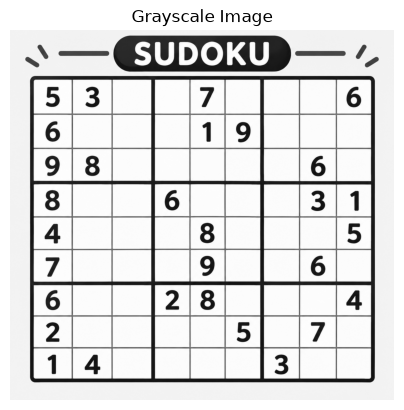

In [3]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

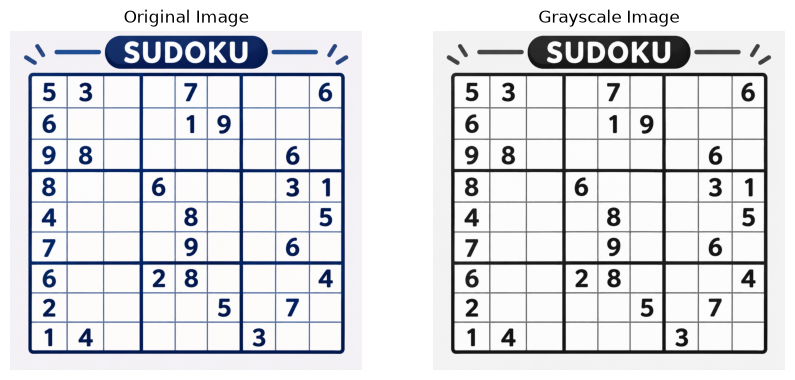

In [4]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

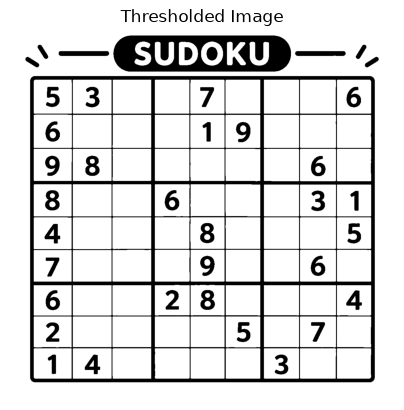

In [5]:
ret, threshold = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY
)

plt.imshow(threshold, cmap="gray")
plt.title("Thresholded Image")
plt.axis("off")
plt.show()

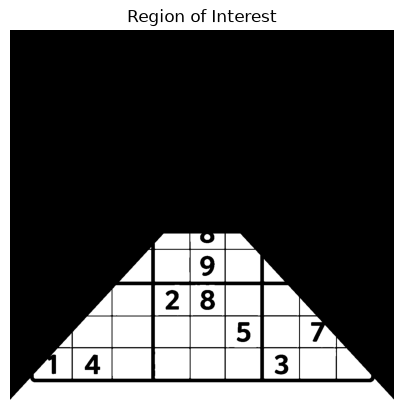

In [6]:
height, width = gray.shape

mask = np.zeros_like(gray)

polygon = np.array([[
    (0, height),
    (width, height),
    (int(width * 0.6), int(height * 0.55)),
    (int(width * 0.4), int(height * 0.55))
]], dtype=np.int32)

cv2.fillPoly(mask, polygon, 255)

roi = cv2.bitwise_and(threshold, mask)

plt.imshow(roi, cmap="gray")
plt.title("Region of Interest")
plt.axis("off")
plt.show()

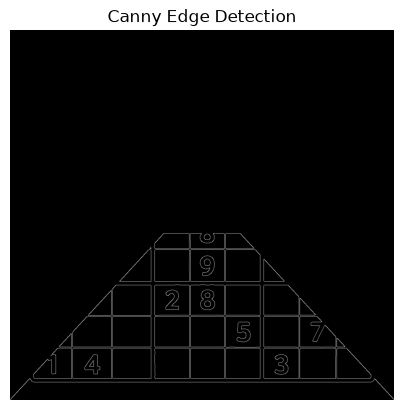

In [7]:
edges = cv2.Canny(roi, 50, 150)

plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

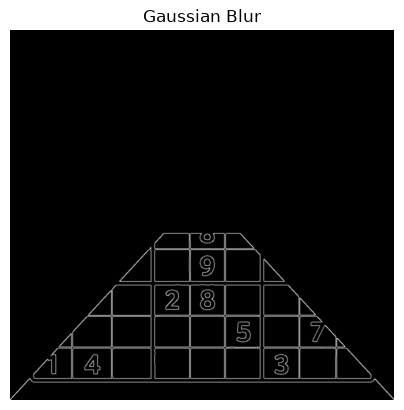

In [8]:
blur = cv2.GaussianBlur(
    edges,
    (5, 5),
    0
)

plt.imshow(blur, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")
plt.show()

In [9]:
lines = cv2.HoughLinesP(
    blur,
    1,
    np.pi / 180,
    threshold=50,
    minLineLength=50,
    maxLineGap=100
)

print("Detected Lines:", lines)

Detected Lines: [[  61 1158 1217 1158]
 [  62 1157 1216 1157]
 [  52 1168 1226 1168]
 [  48 1172 1230 1172]
 [  50 1170 1228 1170]
 [  49 1171 1229 1171]
 [  59 1160 1219 1160]
 [  60 1159 1218 1159]
 [ 161 1053 1117 1053]
 [ 157 1055 1121 1055]
 [ 154 1057 1123 1057]
 [  51 1169 1227 1169]
 [  63 1156 1203 1156]
 [ 152 1059 1125 1059]
 [ 161 1054 1117 1054]
 [ 251  952 1026  952]
 [ 250  953 1027  953]
 [ 253  950 1024  950]
 [ 153 1058 1124 1058]
 [ 155 1056 1123 1056]
 [ 161 1052 1117 1052]
 [ 252  951 1025  951]
 [ 255  949 1022  949]
 [ 161 1051 1117 1051]
 [ 258  948 1019  948]
 [ 258  947 1019  947]
 [ 258  946 1019  946]
 [ 347  848  930  848]
 [ 351  845  926  845]
 [ 348  847  929  847]
 [ 467  945 1019  945]
 [ 346  849  931  849]
 [ 362  835  915  835]
 [ 349  846  928  846]
 [ 362  837  913  837]
 [ 362  833  915  833]
 [ 758  673 1277 1229]
 [ 362  834  915  834]
 [ 766  673 1161 1097]
 [ 362  836  915  836]
 [ 463  724  821  730]
 [ 455  731  822  731]
 [ 133 1079  511  

In [10]:
lines = cv2.HoughLinesP(
    blur,
    1,
    np.pi / 180,
    threshold=50,
    minLineLength=50,
    maxLineGap=100
)

print("Detected Lines:", lines)

Detected Lines: [[  61 1158 1217 1158]
 [  62 1157 1216 1157]
 [  52 1168 1226 1168]
 [  48 1172 1230 1172]
 [  50 1170 1228 1170]
 [  49 1171 1229 1171]
 [  59 1160 1219 1160]
 [  60 1159 1218 1159]
 [ 161 1053 1117 1053]
 [ 157 1055 1121 1055]
 [ 154 1057 1123 1057]
 [  51 1169 1227 1169]
 [  63 1156 1203 1156]
 [ 152 1059 1125 1059]
 [ 161 1054 1117 1054]
 [ 251  952 1026  952]
 [ 250  953 1027  953]
 [ 253  950 1024  950]
 [ 153 1058 1124 1058]
 [ 155 1056 1123 1056]
 [ 161 1052 1117 1052]
 [ 252  951 1025  951]
 [ 255  949 1022  949]
 [ 161 1051 1117 1051]
 [ 258  948 1019  948]
 [ 258  947 1019  947]
 [ 258  946 1019  946]
 [ 347  848  930  848]
 [ 351  845  926  845]
 [ 348  847  929  847]
 [ 467  945 1019  945]
 [ 346  849  931  849]
 [ 362  835  915  835]
 [ 349  846  928  846]
 [ 362  837  913  837]
 [ 362  833  915  833]
 [ 758  673 1277 1229]
 [ 362  834  915  834]
 [ 766  673 1161 1097]
 [ 362  836  915  836]
 [ 463  724  821  730]
 [ 455  731  822  731]
 [ 133 1079  511  